In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from wordcloud import WordCloud

from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.cluster import KMeans


from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

import warnings
warnings.filterwarnings("ignore")


#### Data Exploration

In [2]:
df = pd.read_csv('AB_NYC_2019.csv')
df

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2


In [3]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [5]:
def unique_values(df):
    print(f"{'#':<4}{'Column':<35}{'Unique Count':<15}{'Dtype'}")
    print('-' * 70)
    for i, col in enumerate(df.columns):
        print(f"{i:<4}{col:<35}{df[col].nunique():<15}{df[col].dtype}")

unique_values(df)

#   Column                             Unique Count   Dtype
----------------------------------------------------------------------
0   id                                 48895          int64
1   name                               47905          object
2   host_id                            37457          int64
3   host_name                          11452          object
4   neighbourhood_group                5              object
5   neighbourhood                      221            object
6   latitude                           19048          float64
7   longitude                          14718          float64
8   room_type                          3              object
9   price                              674            int64
10  minimum_nights                     109            int64
11  number_of_reviews                  394            int64
12  last_review                        1764           object
13  reviews_per_month                  937            float64
14  calculated_ho

In [6]:
df.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

##### Data Cleaning

In [8]:
df.fillna({'reviews_per_month': 0}, inplace= True)

df['reviews_per_month'].isnull().sum()

np.int64(0)

In [9]:
df.drop(['name','id', 'last_review', 'host_name'], axis = 1, inplace= True)

In [10]:
df.dropna(inplace= True)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   host_id                         48895 non-null  int64  
 1   neighbourhood_group             48895 non-null  object 
 2   neighbourhood                   48895 non-null  object 
 3   latitude                        48895 non-null  float64
 4   longitude                       48895 non-null  float64
 5   room_type                       48895 non-null  object 
 6   price                           48895 non-null  int64  
 7   minimum_nights                  48895 non-null  int64  
 8   number_of_reviews               48895 non-null  int64  
 9   reviews_per_month               48895 non-null  float64
 10  calculated_host_listings_count  48895 non-null  int64  
 11  availability_365                48895 non-null  int64  
dtypes: float64(3), int64(6), object(

#### Data Visualization

Text(0, 0.5, 'Count')

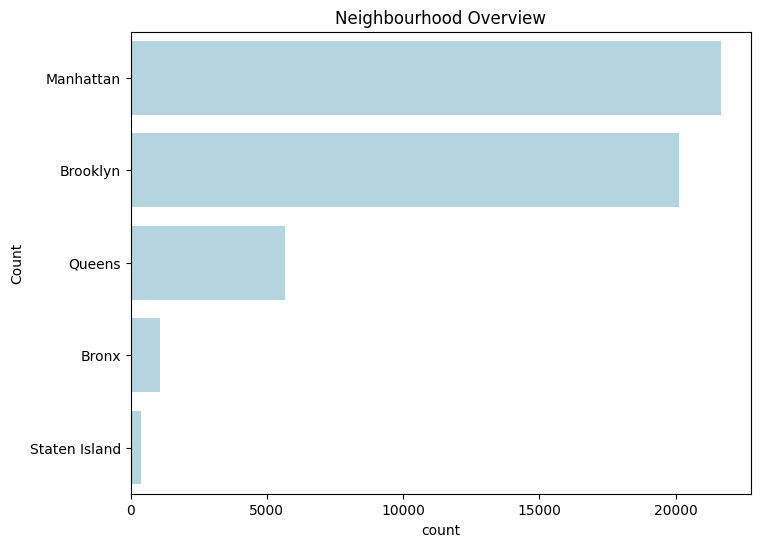

In [12]:
plt.figure(figsize = (8, 6))
sns.countplot( y = 'neighbourhood_group',
              data = df,
              order = df['neighbourhood_group'].value_counts().nlargest().index,
              color = 'lightblue')
plt.title('Neighbourhood Overview')
plt.ylabel('Count')

Text(0, 0.5, 'Count')

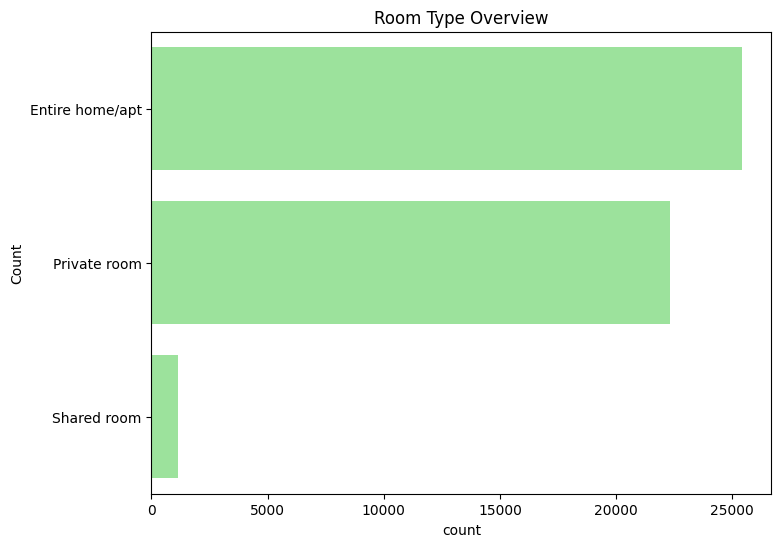

In [13]:
plt.figure(figsize = (8, 6))
sns.countplot( y = 'room_type',
              data = df,
              order = df['room_type'].value_counts().nlargest().index,
              color = 'lightgreen')
plt.title('Room Type Overview')
plt.ylabel('Count')

<Axes: title={'center': 'New York Airbnb Coordinates'}, xlabel='latitude', ylabel='longitude'>

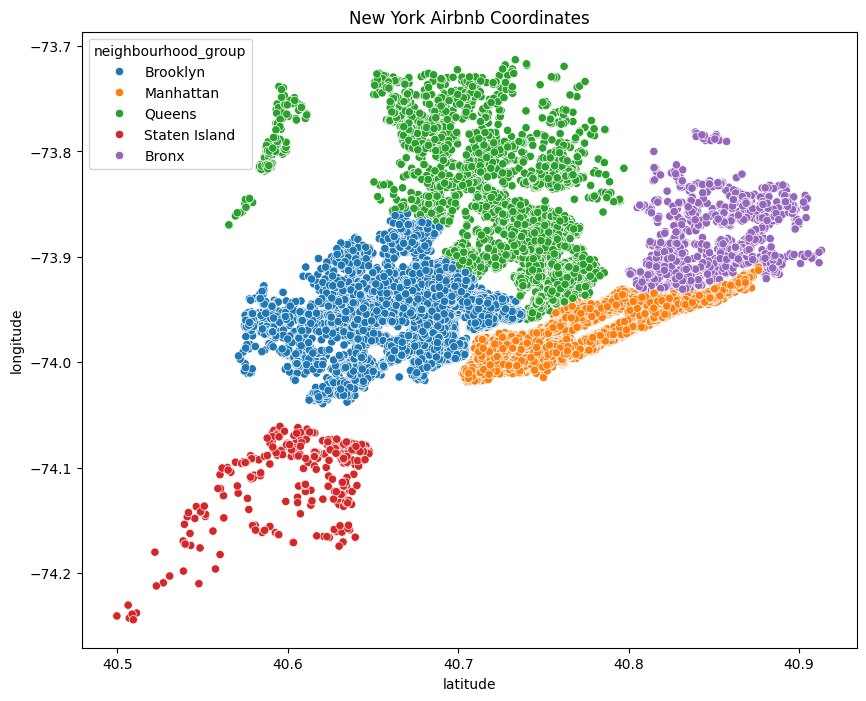

In [14]:
plt.figure(figsize = (10, 8))
plt.title('New York Airbnb Coordinates')
sns.scatterplot(x = 'latitude', y = 'longitude', hue = 'neighbourhood_group', 
               data = df)

<Axes: title={'center': 'New York Airbnb Room Types'}, xlabel='latitude', ylabel='longitude'>

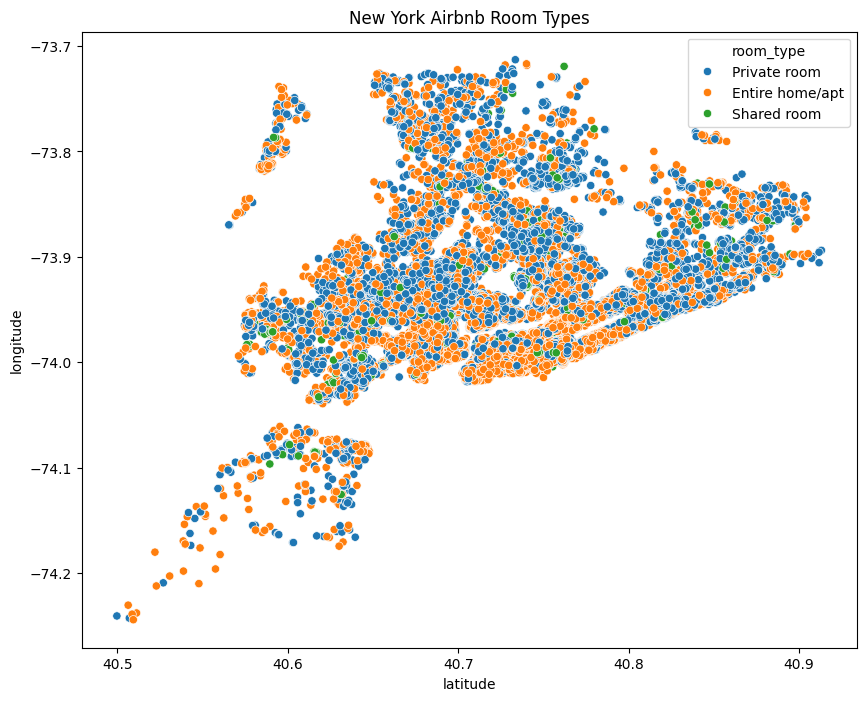

In [15]:
plt.figure(figsize = (10, 8))
plt.title('New York Airbnb Room Types')
sns.scatterplot(x='latitude', y='longitude', hue='room_type', data = df)

In [16]:
df_rules = pd.get_dummies(df[['neighbourhood_group', 'room_type']])
frequent_items = apriori(df_rules, min_support=0.05, use_colnames=True)
rules = association_rules(frequent_items, metric="lift", min_threshold=1.0)
rules.sort_values('confidence', ascending=False).head()


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
2,(neighbourhood_group_Manhattan),(room_type_Entire home/apt),0.443011,0.519665,0.269946,0.609344,1.172572,1.0,0.039729,1.229561,0.264231,0.389684,0.186702,0.564403
5,(neighbourhood_group_Queens),(room_type_Private room),0.115881,0.456611,0.068964,0.595129,1.303360,1.0,0.016052,1.342128,0.263259,0.136962,0.254915,0.373082
3,(room_type_Entire home/apt),(neighbourhood_group_Manhattan),0.519665,0.443011,0.269946,0.519462,1.172572,1.0,0.039729,1.159095,0.306398,0.389684,0.137258,0.564403
1,(neighbourhood_group_Brooklyn),(room_type_Private room),0.411167,0.456611,0.207220,0.503979,1.103739,1.0,0.019476,1.095496,0.159618,0.313704,0.087172,0.478900
0,(room_type_Private room),(neighbourhood_group_Brooklyn),0.456611,0.411167,0.207220,0.453821,1.103739,1.0,0.019476,1.078095,0.172967,0.313704,0.072438,0.478900


Text(0.5, 1.0, 'Word Cloud of Neighbourhoods')

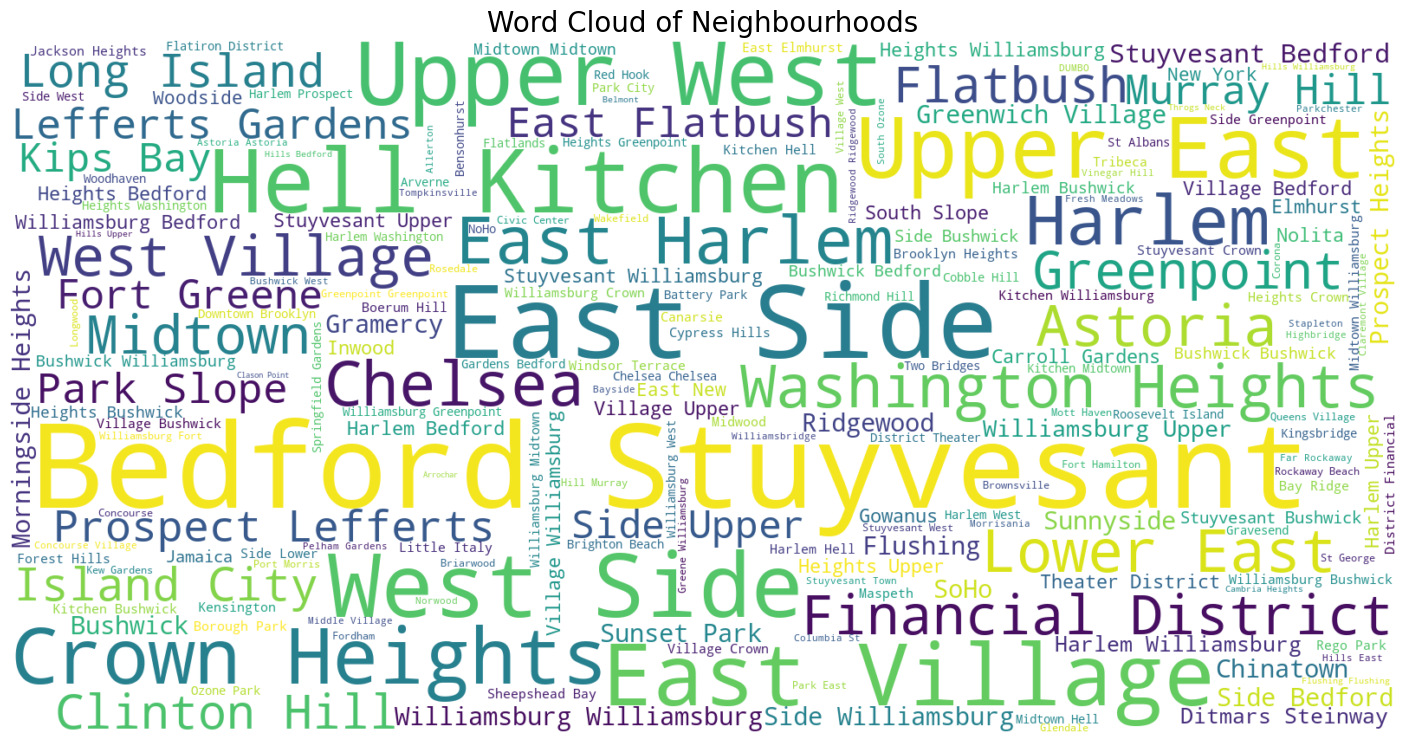

In [ ]:
plt.subplots(figsize = (20, 9))
wordcloud = WordCloud(background_color = 'white', width = 1600, height = 800).generate(' '.join(df['neighbourhood'].values))
plt.imshow(wordcloud, interpolation = 'bilinear')
plt.axis('off')
plt.title('Word Cloud of Neighbourhoods', fontsize = 20)

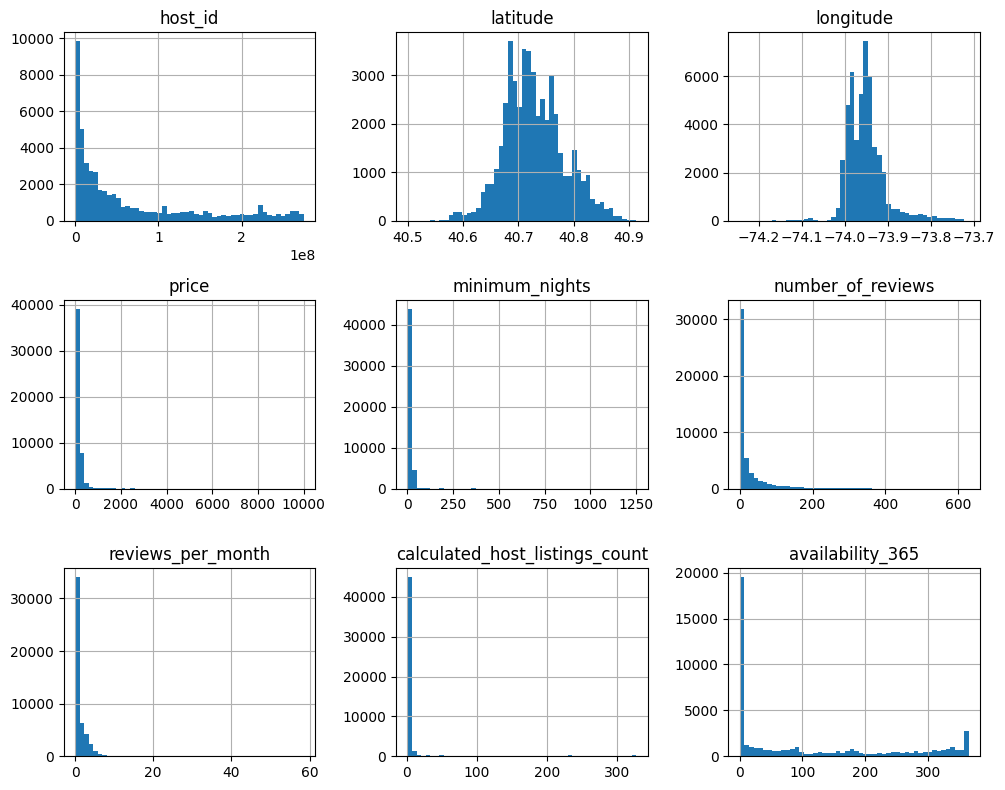

In [18]:
df.hist(bins = 50, figsize= (10, 8))
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Correlation Matrix')

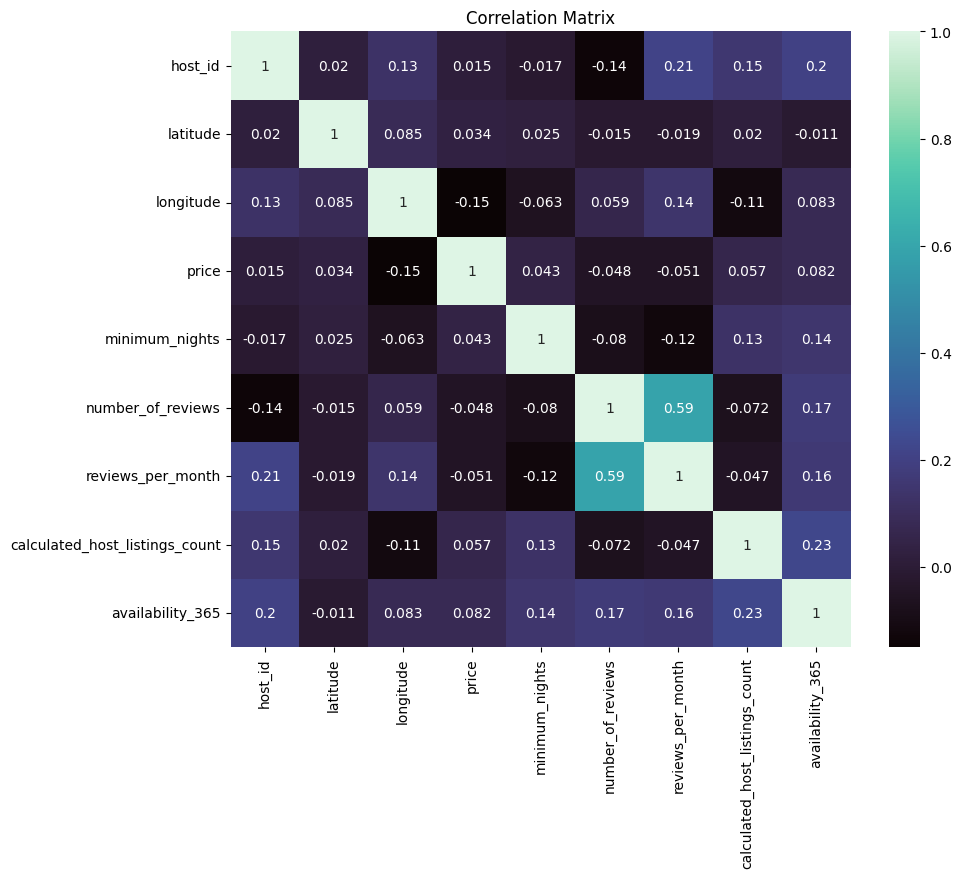

In [19]:
num_df = df.select_dtypes(exclude = 'object')
df_corr = num_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(df_corr, annot = True, cmap = 'mako')
plt.title("Correlation Matrix")

#### Data Preprocessing

In [20]:
df.drop(['host_id','latitude','longitude','neighbourhood','number_of_reviews','reviews_per_month'], axis = 1, inplace=True)

In [21]:
df = df[(df['price'] <= 1000) & (df['minimum_nights'] <= 365)]

In [22]:
categorical_cols = df.select_dtypes('object').columns

for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

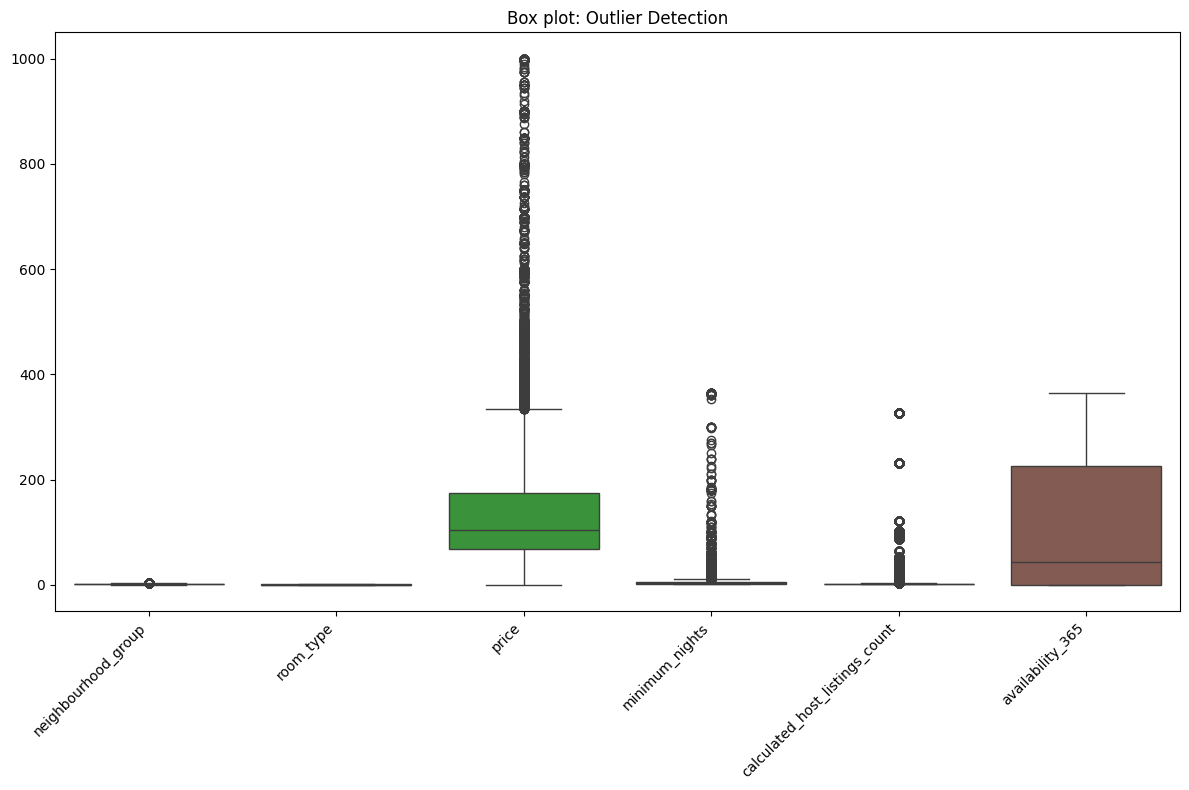

In [23]:
# Box plot to check outlier
plt.figure(figsize=(12, 8))
sns.boxplot(data=df)

plt.title('Box plot: Outlier Detection')
plt.xticks(rotation=45, ha='right')  
plt.tight_layout()  
plt.show()

In [24]:
x = df.drop(['price'], axis = 1).values
y = df['price'].values

In [25]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state= 42)

In [26]:
rc = RobustScaler()
x_train = rc.fit_transform(x_train)
x_test = rc.transform(x_test)

#### Data Modeling, Prediction

##### Linear Regression

In [27]:
# train model
lr = LinearRegression()
lr.fit(x_train, y_train)

# show actual & predcited values
lr_pred = lr.predict(x_test)
lr_plot = pd.DataFrame({'Actual Value': y_test, 'Predicted Value': lr_pred})

lr_plot.head()

,Actual Value,Predicted Value
0,150,199.631053
1,478,198.404382
2,139,208.052176
3,60,84.177225
4,250,84.391823


In [28]:
lr_pred = lr.predict(x_test)
r2 = r2_score(y_test, lr_pred)
rmse = root_mean_squared_error(y_test, lr_pred)
mae = mean_absolute_error(y_test, lr_pred)  
print('Linear Regression Metrics ')
print(f'R2 Score: {round(r2* 100, 2)}%')
print(f'RMSE: {round(rmse, 2)}%')
print(f'MAE: {round(mae, 2)}%')

Linear Regression Metrics 
R2 Score: 24.15%
RMSE: 98.91%
MAE: 60.01%


##### XGBoostRegressor

In [29]:
xgb = XGBRegressor()
xgb.fit(x_train, y_train)

xg_pred = xgb.predict(x_test)
xg_plot = pd.DataFrame({'Actual Value': y_test, 'Predicted Value': xg_pred})

xg_plot.head(5)

,Actual Value,Predicted Value
0,150,182.370773
1,478,265.127777
2,139,233.449631
3,60,100.922882
4,250,98.771118


In [30]:
xg_pred = xgb.predict(x_test)
r2 = r2_score(y_test, xg_pred)
rmse = root_mean_squared_error(y_test, xg_pred)
mae = mean_absolute_error(y_test, xg_pred)  
print('XGBoost Metrics: ')
print(f'R2 Score: {round(r2* 100, 2)}%')
print(f'RMSE: {round(rmse, 2)}%')
print(f'MAE: {round(mae, 2)}%')

XGBoost Metrics: 
R2 Score: 37.12%
RMSE: 90.06%
MAE: 52.39%
